# Low-Rank RNN: DEER vs Broyden variants

A low-rank RNN with weight matrix $J = M N^T$ of rank $R \ll N$ defines
the dynamics:

$$x_t = a \, x_{t-1} + \frac{\Delta t}{\tau} M N^T \phi(x_{t-1}) + \epsilon_t$$

where $x_t \in \mathbb{R}^N$, $a = 1 - \Delta t / \tau$, and $\epsilon_t$ is noise.

The Jacobian is $a I_N + \frac{\Delta t}{\tau} M N^T \text{diag}(\phi'(x))$,
which is **diagonal + rank R** — ideal for Broyden-DEER.

This avoids the projection to $z_t \in \mathbb{R}^R$ used in
[Pals et al. (NeurIPS 2024)](https://arxiv.org/abs/2406.16749),
allowing unrestricted noise covariance.

**Goal**: compare convergence on this dynamics across:
- DEER (full & quasi)
- Broyden-DEER
- Accelerated Broyden
- Full-Broyden (global Woodbury)
- Jacobi, Picard baselines

In [19]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src"))

from algs.deer import deer_alg, picard_alg, jacobi_alg, get_residual
from algs.broyden_deer import broyden_deer_alg
from algs.full_broyden import full_broyden_deer_alg
from algs.accelerated_broyden import accelerated_broyden_deer_alg
from dynamics.low_rank_rnn import LowRankRNN

## Low-Rank RNN setup

We set N=100 neurons with rank R=3 connectivity, matching the
hippocampal data experiments in Pals et al.
The gain $g$ controls the spectral radius of $J$.

In [21]:
N    = 500    # number of neurons
R    = 3      # rank of weight matrix
T    = 1000   # sequence length
tau  = 10.0
dt   = 1.0
g    = 0.8    # gain (spectral radius control)
seed = 42

key = jr.PRNGKey(seed)
k1, k2, k3, k4 = jr.split(key, 4)

# Build low-rank RNN
rnn = LowRankRNN(N, R, key=k1, tau=tau, dt=dt, g=g, phi="tanh")
deer_fxn = rnn.deer_fxn

print(f"N = {N}, R = {R}, T = {T}")
print(f"a = {rnn.a:.3f}, dt/tau = {rnn.dt_over_tau:.3f}, g = {g}")
print(f"M shape: {rnn.M.shape}, Nt shape: {rnn.Nt.shape}")

N = 500, R = 3, T = 1000
a = 0.900, dt/tau = 0.100, g = 0.8
M shape: (500, 3), Nt shape: (500, 3)


In [22]:
# Noise level and initial conditions
sigma_noise = 0.1

initial_state = jnp.zeros(N)
drivers       = sigma_noise * jr.normal(k2, (T, N))   # noise as drivers
states_guess  = jr.normal(k3, (T, N)) * 0.1           # small random guess

# Sanity check
out = deer_fxn(initial_state, drivers[0])
print(f"Output shape: {out.shape}, all finite: {jnp.all(jnp.isfinite(out))}")

Output shape: (500,), all finite: True


## Sequential rollout (reference)

Sequential trajectory shape: (1000, 500)


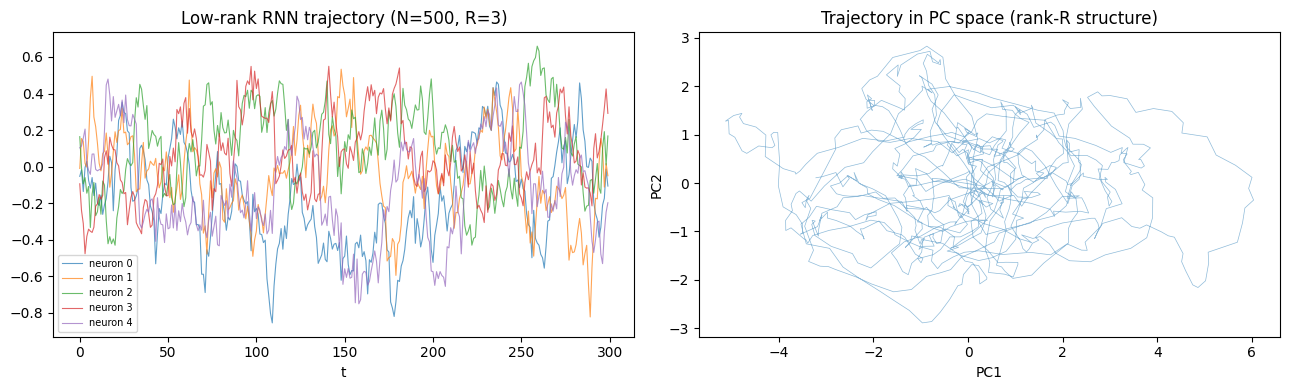

In [23]:
@jax.jit
def run_sequential(init, drivers):
    def step(state, driver):
        new = deer_fxn(state, driver)
        return new, new
    _, trajectory = jax.lax.scan(step, init, drivers)
    return trajectory

seq_trajectory = run_sequential(initial_state, drivers)
print(f"Sequential trajectory shape: {seq_trajectory.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Show a few neuron traces
for i in range(5):
    axes[0].plot(seq_trajectory[:300, i], alpha=0.7, linewidth=0.8, label=f'neuron {i}')
axes[0].set_title(f'Low-rank RNN trajectory (N={N}, R={R})')
axes[0].set_xlabel('t'); axes[0].legend(fontsize=7)

# Project onto top PCs to see low-rank structure
U, s, Vt = jnp.linalg.svd(seq_trajectory - seq_trajectory.mean(0), full_matrices=False)
pcs = (seq_trajectory - seq_trajectory.mean(0)) @ Vt[:3].T
axes[1].plot(pcs[:, 0], pcs[:, 1], alpha=0.5, linewidth=0.5)
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].set_title('Trajectory in PC space (rank-R structure)')
plt.tight_layout()

## Jacobian structure

The Jacobian $\partial f / \partial x = a I + \frac{\Delta t}{\tau} M N^T \text{diag}(\phi')$
is diagonal + rank R. Its singular value spectrum should show
R large values and N-R values equal to $|a|$.

Top-5 singular values: [1.5815921  1.4952344  1.4217271  0.9000015  0.90000135]
Remaining cluster around a = 0.900
Min sv: 0.4662, Max sv: 1.5816


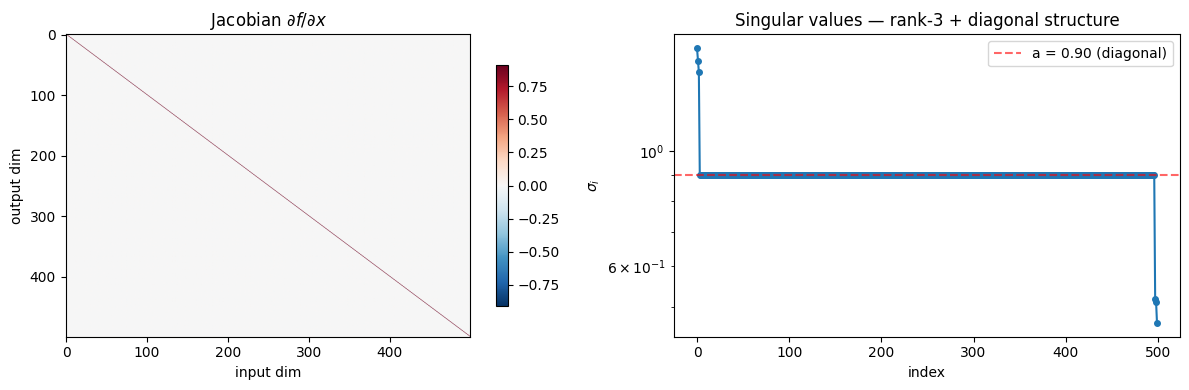

In [24]:
typical_state  = seq_trajectory[200]
typical_driver = drivers[201]
J = jax.jacfwd(deer_fxn)(typical_state, typical_driver)

_, sv, _ = jnp.linalg.svd(J)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im = axes[0].imshow(J, aspect='auto', cmap='RdBu_r',
                    vmin=-jnp.abs(J).max(), vmax=jnp.abs(J).max())
axes[0].set_title(r'Jacobian $\partial f / \partial x$')
axes[0].set_xlabel('input dim'); axes[0].set_ylabel('output dim')
plt.colorbar(im, ax=axes[0], shrink=0.8)

axes[1].semilogy(sv, 'o-', markersize=4)
axes[1].axhline(rnn.a, color='red', ls='--', alpha=0.6,
                label=f'a = {rnn.a:.2f} (diagonal)')
axes[1].set_xlabel('index'); axes[1].set_ylabel(r'$\sigma_i$')
axes[1].set_title(f'Singular values — rank-{R} + diagonal structure')
axes[1].legend()

print(f"Top-{R+2} singular values: {sv[:R+2]}")
print(f"Remaining cluster around a = {rnn.a:.3f}")
print(f"Min sv: {sv[-1]:.4f}, Max sv: {sv[0]:.4f}")

plt.tight_layout()

## Baseline convergence: DEER, quasi-DEER, Jacobi, Picard

In [25]:
max_n = 100
iters = list(range(1, max_n + 1))

In [26]:
# DEER baselines — use mf_val (7th return value) directly
*_, deer_errs   = deer_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)
*_, quasi_errs  = deer_alg(deer_fxn, initial_state, states_guess, drivers, max_n, quasi=True, full_trace=True)
*_, jacobi_errs = jacobi_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)
*_, picard_errs = picard_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)

deer_errs   = list(np.array(deer_errs))
quasi_errs  = list(np.array(quasi_errs))
jacobi_errs = list(np.array(jacobi_errs))
picard_errs = list(np.array(picard_errs))

In [59]:
# Iterations to convergence
for name, alg, kwargs in [
    ("DEER",       deer_alg,   {}),
    ("quasi-DEER", deer_alg,   dict(quasi=True)),
    ("Jacobi",     jacobi_alg, {}),
    ("Picard",     picard_alg, {}),
]:
    _, _, nb_iters, *_ = alg(deer_fxn, initial_state, states_guess, drivers,
                              num_iters=max_n, tol=5e-4, **kwargs)
    nb = int(nb_iters) if nb_iters is not None else max_n
    print(f"{name}: converged in {nb} iterations")

DEER: converged in 6 iterations
quasi-DEER: converged in 100 iterations
Jacobi: converged in 100 iterations
Picard: converged in 100 iterations


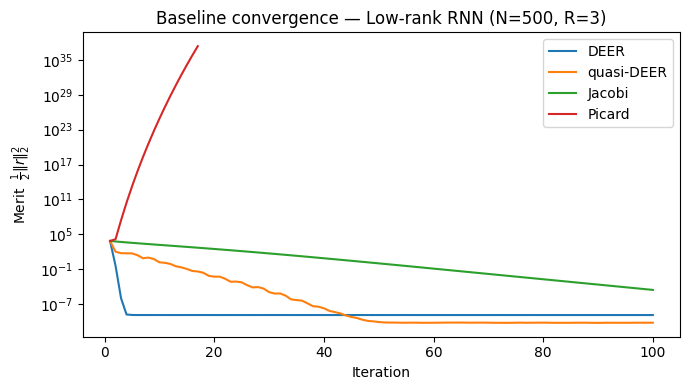

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.semilogy(iters, deer_errs,   label="DEER")
ax.semilogy(iters, quasi_errs,  label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, label="Jacobi")
ax.semilogy(iters, picard_errs, label="Picard")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Merit  $\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Baseline convergence — Low-rank RNN (N={N}, R={R})")
ax.legend()
plt.tight_layout()

## Broyden-DEER convergence

The Jacobian is $aI + \text{rank-R}$, so Broyden-DEER with `m >= R` should
capture the full structure. Compare across init schemes and window sizes.

In [ ]:
bd_m = 3
bd_init = "rescaled_identity"
bd_k = 0.0

*_, bd_errs = broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    m=bd_m, init=bd_init, k=bd_k, full_trace=True)
bd_errs = list(np.array(bd_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, bd_errs, "-", color="tab:blue", linewidth=1.8,
            label=f"Broyden-DEER (m={bd_m}, {bd_init}, k={bd_k})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Broyden-DEER convergence  |  Low-rank RNN (N={N}, R={R})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Broyden-DEER with low_rank init

Since we know the Jacobian is exactly rank R, `init="low_rank"` with `m=R`
should capture the exact Jacobian from iteration 0.

In [ ]:
# low_rank init at m = R
*_, lr_errs = broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    m=R, init="low_rank", full_trace=True)
lr_errs = list(np.array(lr_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, lr_errs, "-", color="tab:purple", linewidth=2,
            label=f"Broyden-DEER (low_rank, m={R})")
ax.semilogy(iters, bd_errs[R]["jac"], "-", color="tab:green", linewidth=1.5,
            label=f"Broyden-DEER (jac, m={R})")
ax.semilogy(iters, deer_errs, "k-", linewidth=2, label="DEER (full Jac)")
ax.semilogy(iters, quasi_errs, "k--", linewidth=1.5, label="quasi-DEER (diag Jac)")

ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"low_rank init exploits rank-{R} structure  |  N={N}")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Accelerated Broyden convergence

In [ ]:
acc_m = 3
acc_k = 0.0
acc_init = "rescaled_identity"

*_, acc_errs = accelerated_broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    m=acc_m, init=acc_init, k=acc_k, full_trace=True, qmem_efficient=True)
acc_errs = list(np.array(acc_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, acc_errs, "-", color="tab:purple", linewidth=1.8,
            label=f"Accel. Broyden (m={acc_m}, k={acc_k}, {acc_init})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Accelerated Broyden  |  Low-rank RNN (N={N}, R={R})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Full-Broyden (global Woodbury) convergence

In [ ]:
fb_k_values    = [3, 5, 10]
fb_init_modes  = ["identity", "rescaled_identity", "jac", "fresh_jac"]
fb_styles      = {"identity": "--", "rescaled_identity": "-.", "jac": "-", "fresh_jac": ":"}
fb_colors      = {"identity": "tab:cyan", "rescaled_identity": "tab:olive",
                  "jac": "tab:green", "fresh_jac": "tab:red"}

fb_errs = {k: {} for k in fb_k_values}
for k in fb_k_values:
    for init_mode in fb_init_modes:
        *_, mf_val = full_broyden_deer_alg(
            deer_fxn, initial_state, states_guess, drivers, max_n,
            k=k, init=init_mode, full_trace=True)
        fb_errs[k][init_mode] = list(np.array(mf_val))

fig, axes = plt.subplots(1, len(fb_k_values), figsize=(5 * len(fb_k_values), 5), sharey=True)

for ax, k in zip(axes, fb_k_values):
    for init_mode in fb_init_modes:
        ax.semilogy(iters, fb_errs[k][init_mode], fb_styles[init_mode],
                    color=fb_colors[init_mode], label=f'{init_mode}', linewidth=1.8)
    ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
    ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
    ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
    ax.set_xlabel("Newton iterations")
    ax.set_title(f"Full-Broyden k={k}")
    ax.legend(fontsize=7); ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
fig.suptitle(f"Full-Broyden convergence  |  Low-rank RNN (N={N}, R={R})", y=1.02)
plt.tight_layout()

## DEER vs sequential: trajectory comparison

In [ ]:
_, deer_final, *_ = deer_alg(deer_fxn, initial_state, states_guess, drivers,
                              num_iters=max_n, tol=5e-4)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Overlay a few neuron traces
for i in range(5):
    axes[0].plot(seq_trajectory[:200, i], 'k-', alpha=0.3, linewidth=1)
    axes[0].plot(deer_final[:200, i], '--', alpha=0.8, linewidth=1)
axes[0].set_title('DEER vs Sequential (first 200 steps)')
axes[0].set_xlabel('t')

# Max absolute error across neurons
err = jnp.abs(deer_final - seq_trajectory)
axes[1].semilogy(jnp.max(err, axis=1), alpha=0.8, linewidth=0.6)
axes[1].set_title(r'Max absolute error $\max_i |x^{\mathrm{DEER}}_t - x^{\mathrm{seq}}_t|$')
axes[1].set_xlabel('t')
plt.tight_layout()

## Scaling: vary N at fixed R

The key advantage of Broyden-DEER: as N grows, DEER needs $O(N^2)$ per-block
Jacobian, but Broyden-DEER with `m=R` stays $O(NR)$.

In [ ]:
N_values = [50, 100, 200]
T_scale  = 500
max_n_scale = 50
iters_scale = list(range(1, max_n_scale + 1))

fig, axes = plt.subplots(1, len(N_values), figsize=(5 * len(N_values), 5), sharey=True)

for ax, Nv in zip(axes, N_values):
    key_v = jr.PRNGKey(Nv)
    kv1, kv2, kv3 = jr.split(key_v, 3)

    rnn_v = LowRankRNN(Nv, R, key=kv1, tau=tau, dt=dt, g=g, phi="tanh")
    f_v = rnn_v.deer_fxn
    x0_v = jnp.zeros(Nv)
    drv_v = sigma_noise * jr.normal(kv2, (T_scale, Nv))
    sg_v  = jr.normal(kv3, (T_scale, Nv)) * 0.1

    # quasi-DEER (diagonal only, no full Jac)
    *_, q_errs = deer_alg(f_v, x0_v, sg_v, drv_v, max_n_scale, quasi=True, full_trace=True)
    # Broyden-DEER with m=R (low_rank init)
    *_, b_errs = broyden_deer_alg(f_v, x0_v, sg_v, drv_v, max_n_scale,
                                   m=R, init="low_rank", full_trace=True)
    # Broyden-DEER with jac init
    *_, j_errs = broyden_deer_alg(f_v, x0_v, sg_v, drv_v, max_n_scale,
                                   m=R, init="jac", full_trace=True)

    ax.semilogy(iters_scale, list(np.array(q_errs)), "k--", linewidth=1.5, label="quasi-DEER")
    ax.semilogy(iters_scale, list(np.array(b_errs)), "-", color="tab:purple", linewidth=1.8,
                label=f"Broyden (low_rank, m={R})")
    ax.semilogy(iters_scale, list(np.array(j_errs)), "-", color="tab:green", linewidth=1.8,
                label=f"Broyden (jac, m={R})")
    ax.set_xlabel("Newton iterations")
    ax.set_title(f"N={Nv}, R={R}")
    ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
fig.suptitle(f"Scaling with N at fixed R={R}, T={T_scale}", y=1.02)
plt.tight_layout()